In [1]:
import os, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from google.colab import drive

drive.mount('/content/drive')
FINAL_PATH = '/content/drive/MyDrive/projet_conso/data/processed/dataset_hourly.parquet'
assert os.path.exists(FINAL_PATH), f'Fichier introuvable : {FINAL_PATH}'

SEED = 42
def set_seed(seed):
    """Fixe toutes les sources d'aléatoire pour des résultats reproductibles."""
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device :', device)

df = pd.read_parquet(FINAL_PATH)
print(f'Dataset : {df.shape[0]:,} lignes × {df.shape[1]} colonnes')

Mounted at /content/drive
Device : cuda
Dataset : 34,587 lignes × 15 colonnes


In [2]:
TARGET  = 'global_active_power'
HORIZON = 24

# Découpage commun à tous les modèles (le test couvre toutes les saisons)
SPLITS = {
    'train': ('2006-12-16', '2008-12-31 23:00'),
    'val':   ('2009-01-01', '2009-12-31 23:00'),
    'test':  ('2010-01-01', '2010-12-31 23:00'),
}

CAL_COLS   = ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos',
              'is_weekend', 'is_holiday']
PAST_COLS  = [TARGET, 'apparent_temperature'] + CAL_COLS   # passé : la température observée est légitime
SCALE_COLS = [TARGET, 'apparent_temperature']


def future_cols(future_temp):
    """Variables des 24 h à prédire.
    future_temp=False : calendrier seul -> scénario réaliste (RÉFÉRENCE).
    future_temp=True  : + température observée -> scénario « météo future parfaite » (oracle, ablation).
    """
    return CAL_COLS + (['apparent_temperature'] if future_temp else [])


def add_cyclic_features(d):
    """Encode heure, jour et mois en sin/cos pour que 23h et 0h soient voisins."""
    d = d.copy()
    d['hour_sin']  = np.sin(2 * np.pi * d['hour'] / 24)
    d['hour_cos']  = np.cos(2 * np.pi * d['hour'] / 24)
    d['dow_sin']   = np.sin(2 * np.pi * d['day_of_week'] / 7)
    d['dow_cos']   = np.cos(2 * np.pi * d['day_of_week'] / 7)
    d['month_sin'] = np.sin(2 * np.pi * (d['month'] - 1) / 12)
    d['month_cos'] = np.cos(2 * np.pi * (d['month'] - 1) / 12)
    return d


df_model = add_cyclic_features(df)

# Normalisation apprise sur le TRAIN uniquement (pas de fuite)
train_stats = df_model.loc[SPLITS['train'][0]:SPLITS['train'][1], SCALE_COLS].agg(['mean', 'std'])
MEANS, STDS = train_stats.loc['mean'], train_stats.loc['std']
df_scaled = df_model.copy()
df_scaled[SCALE_COLS] = (df_scaled[SCALE_COLS] - MEANS) / STDS


def to_kw(z):
    """Repasse la target normalisée en kW."""
    return z * STDS[TARGET] + MEANS[TARGET]


print(train_stats.round(3))

      global_active_power  apparent_temperature
mean                1.111                 8.632
std                 0.966                 7.713


In [3]:
def build_windows(window, future_temp=False):
    """Construit tous les échantillons (passé -> 24 h futures) sur toute la série,
    puis les répartit en train/val/test selon la date des heures à prédire."""
    past = df_scaled[PAST_COLS].to_numpy(np.float32)
    fut  = df_scaled[future_cols(future_temp)].to_numpy(np.float32)
    y    = df_scaled[TARGET].to_numpy(np.float32)
    real = df_scaled['is_imputed'].to_numpy() == 0
    times = df_scaled.index

    first = max(window, 168)                               # 168 h d'historique pour la baseline J-7
    t0 = np.arange(first, len(df_scaled) - HORIZON + 1)    # 1re heure prédite de chaque échantillon
    fut_idx = t0[:, None] + np.arange(HORIZON)

    data = {}
    for name, (start, end) in SPLITS.items():
        keep = (times[t0] >= pd.Timestamp(start)) & (times[t0 + HORIZON - 1] <= pd.Timestamp(end))
        s, fi = t0[keep], fut_idx[keep]
        pi = s[:, None] - window + np.arange(window)
        data[name] = dict(past=past[pi], fut=fut[fi], y=y[fi], mask=real[fi],
                          j1=y[fi - 24], j7=y[fi - 168], start=times[s])
    return data


def to_loader(d, shuffle, batch_size=256):
    """Le masque voyage avec chaque échantillon pour être utilisé dans la perte."""
    ds = TensorDataset(torch.from_numpy(d['past']), torch.from_numpy(d['fut']),
                       torch.from_numpy(d['y']), torch.from_numpy(d['mask']))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


_cache = {}
def get_data(window, future_temp=False):
    """Fenêtres mises en cache : chaque combinaison n'est construite qu'une fois."""
    key = (window, future_temp)
    if key not in _cache:
        _cache[key] = build_windows(window, future_temp)
    return _cache[key]


data = get_data(168)
for k, d in data.items():
    print(f"{k:5s} : passé {d['past'].shape}  futur {d['fut'].shape}  cible {d['y'].shape}")

train : passé (17719, 168, 10)  futur (17719, 24, 8)  cible (17719, 24)
val   : passé (8737, 168, 10)  futur (8737, 24, 8)  cible (8737, 24)
test  : passé (7894, 168, 10)  futur (7894, 24, 8)  cible (7894, 24)


In [4]:
class LSTMForecaster(nn.Module):
    """Encodeur LSTM sur le passé + infos futures connues -> 24 prédictions.

    1. Le LSTM lit la séquence passée heure par heure et la résume dans son état caché final.
    2. Ce résumé est concaténé au calendrier et à la météo des 24 h à prédire.
    3. Une tête dense produit les 24 valeurs d'un coup (stratégie directe).
    """
    def __init__(self, n_past, n_fut, horizon=HORIZON, hidden=64, layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(n_past, hidden, num_layers=layers, batch_first=True,
                            dropout=dropout if layers > 1 else 0.0)
        self.head = nn.Sequential(
            nn.Linear(hidden + horizon * n_fut, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, horizon),                          # sortie linéaire (régression)
        )

    def forward(self, past, fut):
        _, (h, _) = self.lstm(past)                           # h : (couches, batch, hidden)
        z = torch.cat([h[-1], fut.flatten(1)], dim=1)         # mémoire du passé + futur connu
        return self.head(z)


model = LSTMForecaster(len(PAST_COLS), len(future_cols(False))).to(device)
print(model)
print('Paramètres :', sum(p.numel() for p in model.parameters()))

LSTMForecaster(
  (lstm): LSTM(10, 64, num_layers=2, batch_first=True, dropout=0.2)
  (head): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=24, bias=True)
  )
)
Paramètres : 88728


In [5]:
def masked_mae(pred, y, mask):
    """MAE calculée uniquement sur les heures réellement mesurées (non imputées)."""
    err = torch.abs(pred - y)[mask]
    return err.mean() if err.numel() > 0 else pred.sum() * 0.0


def run_epoch(model, loader, optimizer=None, clip=1.0):
    """Une passe sur le loader : entraînement si optimizer est donné, sinon évaluation."""
    training = optimizer is not None
    model.train(training)
    total, count = 0.0, 0
    with torch.set_grad_enabled(training):
        for past, fut, yb, mb in loader:
            past, fut, yb, mb = past.to(device), fut.to(device), yb.to(device), mb.to(device)
            loss = masked_mae(model(past, fut), yb, mb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), clip)   # évite l'explosion des gradients
                optimizer.step()
            n = int(mb.sum())
            total += loss.item() * n
            count += n
    return total / max(count, 1)


def train_model(model, train_loader, val_loader, lr=1e-3, epochs=100, patience=10, verbose=True):
    """Adam, lr réduit sur plateau, early stopping sur la validation."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=3)
    best, state, wait, best_epoch = float('inf'), None, 0, 0
    history = {'train': [], 'val': []}

    for epoch in range(1, epochs + 1):
        tr = run_epoch(model, train_loader, optimizer)
        va = run_epoch(model, val_loader)
        scheduler.step(va)
        history['train'].append(tr); history['val'].append(va)
        if verbose:
            print(f'Époque {epoch:3d} | train {tr:.4f} | val {va:.4f} | lr {optimizer.param_groups[0]["lr"]:.1e}')
        if va < best - 1e-5:
            best, wait, best_epoch = va, 0, epoch
            state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(state)
    history['best_epoch'] = best_epoch
    return history


def predict(model, d, batch_size=1024):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(d['y']), batch_size):
            p = torch.from_numpy(d['past'][i:i + batch_size]).to(device)
            f = torch.from_numpy(d['fut'][i:i + batch_size]).to(device)
            out.append(model(p, f).cpu().numpy())
    return np.concatenate(out)


def compute_metrics(y_true, y_pred, mask):
    """Métriques en kW, uniquement sur les heures réellement mesurées."""
    t, p = y_true[mask], y_pred[mask]
    err = p - t
    return {
        'MAE (kW)':  np.mean(np.abs(err)),
        'RMSE (kW)': np.sqrt(np.mean(err ** 2)),
        'MAPE (%)':  np.mean(np.abs(err) / t) * 100,
        'WAPE (%)':  np.sum(np.abs(err)) / np.sum(t) * 100,
    }

In [6]:
tuning = pd.DataFrame()


def run_lstm(config, window=168, hidden=64, layers=2, dropout=0.2, lr=1e-3,
             future_temp=False, seed=SEED):
    """Entraîne une variante et note sa performance sur la VALIDATION. Le test n'est jamais touché ici."""
    d = get_data(window, future_temp)
    set_seed(seed)
    m = LSTMForecaster(len(PAST_COLS), len(future_cols(future_temp)),
                       hidden=hidden, layers=layers, dropout=dropout).to(device)
    h = train_model(m, to_loader(d['train'], True), to_loader(d['val'], False), lr=lr, verbose=False)
    val = compute_metrics(to_kw(d['val']['y']), to_kw(predict(m, d['val'])), d['val']['mask'])

    row = f'{config} | seed {seed}'
    tuning.loc[row, 'Config'] = config
    tuning.loc[row, 'MAE val'] = val['MAE (kW)']
    tuning.loc[row, 'RMSE val'] = val['RMSE (kW)']
    tuning.loc[row, 'Époque'] = h['best_epoch']
    tuning.loc[row, 'Paramètres'] = sum(p.numel() for p in m.parameters())
    print(f'{row:40s} -> MAE val {val["MAE (kW)"]:.3f}  (époque {h["best_epoch"]})')
    return m


def summarize():
    """Moyenne et écart-type de la MAE validation sur les seeds, par configuration."""
    return (tuning.groupby('Config')
                  .agg(MAE_val=('MAE val', 'mean'), ecart_type=('MAE val', 'std'),
                       seeds=('MAE val', 'count'), parametres=('Paramètres', 'first'))
                  .sort_values('MAE_val').round(4))


CONFIGS = {
    'Référence 168h-64-2c': dict(),
    'Fenêtre 48h':          dict(window=48),
    'Fenêtre 336h':         dict(window=336),
    '128 neurones':         dict(hidden=128),
    '1 couche':             dict(layers=1),
    'Dropout 0.4':          dict(dropout=0.4),
    'lr 3e-4':              dict(lr=3e-4),
}
for name, cfg in CONFIGS.items():
    for s in [42, 1, 2]:
        run_lstm(name, seed=s, **cfg)

summarize()

Référence 168h-64-2c | seed 42           -> MAE val 0.456  (époque 9)
Référence 168h-64-2c | seed 1            -> MAE val 0.463  (époque 10)
Référence 168h-64-2c | seed 2            -> MAE val 0.462  (époque 5)
Fenêtre 48h | seed 42                    -> MAE val 0.458  (époque 7)
Fenêtre 48h | seed 1                     -> MAE val 0.460  (époque 8)
Fenêtre 48h | seed 2                     -> MAE val 0.463  (époque 10)
Fenêtre 336h | seed 42                   -> MAE val 0.452  (époque 9)
Fenêtre 336h | seed 1                    -> MAE val 0.455  (époque 11)
Fenêtre 336h | seed 2                    -> MAE val 0.454  (époque 10)
128 neurones | seed 42                   -> MAE val 0.450  (époque 7)
128 neurones | seed 1                    -> MAE val 0.465  (époque 6)
128 neurones | seed 2                    -> MAE val 0.455  (époque 7)
1 couche | seed 42                       -> MAE val 0.458  (époque 10)
1 couche | seed 1                        -> MAE val 0.453  (époque 11)
1 couche | see

,MAE_val,ecart_type,seeds,parametres
Config,,,,
Dropout 0.4,0.4535,0.0035,3,88728.0
Fenêtre 336h,0.4537,0.0015,3,88728.0
1 couche,0.4568,0.0029,3,55448.0
128 neurones,0.4568,0.0080,3,247960.0
Référence 168h-64-2c,0.4602,0.0035,3,88728.0
Fenêtre 48h,0.4603,0.0029,3,88728.0
lr 3e-4,0.4677,0.0024,3,88728.0


In [7]:
for s in [42, 1, 2]:
    run_lstm('336h + dropout 0.4', window=336, dropout=0.4, seed=s)
summarize()

336h + dropout 0.4 | seed 42             -> MAE val 0.451  (époque 11)
336h + dropout 0.4 | seed 1              -> MAE val 0.453  (époque 10)
336h + dropout 0.4 | seed 2              -> MAE val 0.454  (époque 7)


,MAE_val,ecart_type,seeds,parametres
Config,,,,
336h + dropout 0.4,0.4523,0.0015,3,88728.0
Dropout 0.4,0.4535,0.0035,3,88728.0
Fenêtre 336h,0.4537,0.0015,3,88728.0
1 couche,0.4568,0.0029,3,55448.0
128 neurones,0.4568,0.0080,3,247960.0
Référence 168h-64-2c,0.4602,0.0035,3,88728.0
Fenêtre 48h,0.4603,0.0029,3,88728.0
lr 3e-4,0.4677,0.0024,3,88728.0


FINAL réaliste | seed 42                 -> MAE val 0.451  (époque 11)
FINAL météo parfaite | seed 42           -> MAE val 0.456  (époque 7)
Prévision toutes les heures (fenêtres glissantes) :


,MAE (kW),RMSE (kW),MAPE (%),WAPE (%)
Persistance J-1,0.558,0.823,68.370,52.562
Persistance J-7,0.576,0.831,73.686,54.248
LSTM (réaliste),0.455,0.644,54.408,42.872
LSTM (météo parfaite),0.455,0.638,54.159,42.842


Prévision une fois par jour, à minuit :


,MAE (kW),RMSE (kW),MAPE (%),WAPE (%)
Persistance J-1,0.558,0.823,68.458,52.619
Persistance J-7,0.576,0.832,73.766,54.316
LSTM (réaliste),0.454,0.645,54.595,42.793
LSTM (météo parfaite),0.454,0.639,53.848,42.815


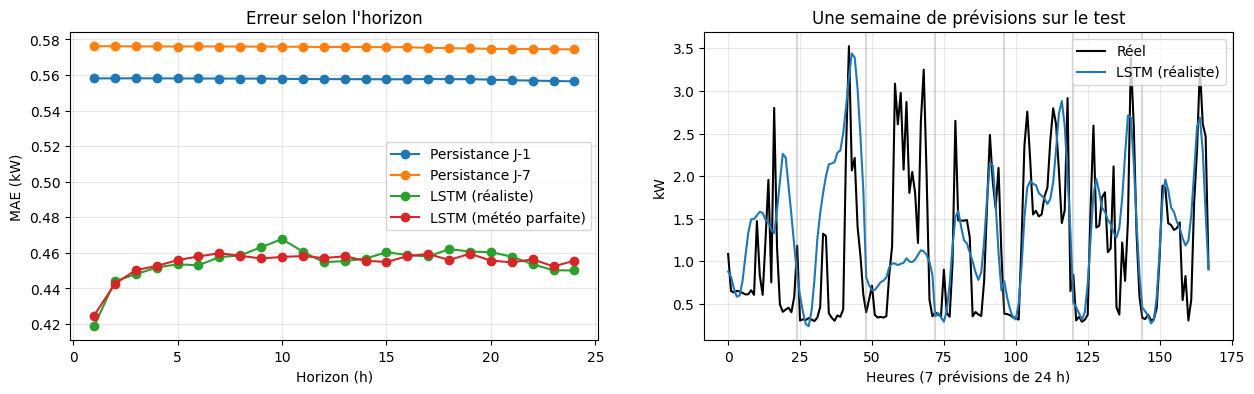

In [10]:
# ==== Configuration choisie sur la VALIDATION (à remplir d'après summarize()) ====
FINAL = dict(window=336, hidden=64, layers=2, dropout=0.4, lr=1e-3)

# Modèle réaliste (calendrier seul pour le futur) + ablation « météo future parfaite »
lstm_real   = run_lstm('FINAL réaliste', future_temp=False, **FINAL)
lstm_oracle = run_lstm('FINAL météo parfaite', future_temp=True, **FINAL)

# ==== Évaluation UNIQUE sur le test ====
test = get_data(FINAL['window'], False)['test']
y_true = to_kw(test['y'])
preds = {
    'Persistance J-1':       to_kw(test['j1']),
    'Persistance J-7':       to_kw(test['j7']),
    'LSTM (réaliste)':       to_kw(predict(lstm_real, test)),
    'LSTM (météo parfaite)': to_kw(predict(lstm_oracle, get_data(FINAL['window'], True)['test'])),
}

results = pd.DataFrame({k: compute_metrics(y_true, p, test['mask']) for k, p in preds.items()}).T.round(3)
print('Prévision toutes les heures (fenêtres glissantes) :')
display(results)

midnight = test['start'].hour == 0
results_daily = pd.DataFrame({k: compute_metrics(y_true[midnight], p[midnight], test['mask'][midnight])
                              for k, p in preds.items()}).T.round(3)
print('Prévision une fois par jour, à minuit :')
display(results_daily)

# ==== Graphiques ====
def mae_by_horizon(y_true, y_pred, mask):
    return np.array([np.abs(y_true[mask[:, h], h] - y_pred[mask[:, h], h]).mean() for h in range(HORIZON)])

hours = np.arange(1, HORIZON + 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for name, p in preds.items():
    axes[0].plot(hours, mae_by_horizon(y_true, p, test['mask']), marker='o', label=name)
axes[0].set_xlabel('Horizon (h)'); axes[0].set_ylabel('MAE (kW)')
axes[0].set_title("Erreur selon l'horizon"); axes[0].legend(); axes[0].grid(alpha=0.3)

idx = np.where(midnight)[0][:7]
axes[1].plot(np.concatenate([y_true[i] for i in idx]), 'k', label='Réel')
axes[1].plot(np.concatenate([preds['LSTM (réaliste)'][i] for i in idx]), label='LSTM (réaliste)')
for d_ in range(1, 7):
    axes[1].axvline(24 * d_, color='grey', alpha=0.3)
axes[1].set_xlabel('Heures (7 prévisions de 24 h)'); axes[1].set_ylabel('kW')
axes[1].set_title('Une semaine de prévisions sur le test'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.show()

# Sauvegarde du modèle retenu
os.makedirs('/content/drive/MyDrive/projet_conso/results', exist_ok=True)
torch.save({
    'model_state_dict': lstm_real.state_dict(),
    'config': FINAL,
    'past_cols': PAST_COLS,
    'future_cols': future_cols(False),
    'target': TARGET,
    'means': MEANS.to_dict(),
    'stds': STDS.to_dict(),
    'horizon': HORIZON,
}, '/content/drive/MyDrive/projet_conso/results/lstm_final.pt')

In [12]:
tr = df_model.loc[SPLITS['train'][0]:SPLITS['train'][1]]
tr = tr[tr['is_imputed'] == 0]
profile = tr.groupby(['day_of_week', 'hour'])[TARGET].mean()

fut_times = test['start'].values[:, None] + np.arange(HORIZON) * np.timedelta64(1, 'h')
ft = pd.DatetimeIndex(fut_times.ravel())
pred_profile = profile.reindex(list(zip(ft.dayofweek, ft.hour))).to_numpy().reshape(-1, HORIZON)

results.loc['Profil moyen (jour × heure)'] = pd.Series(compute_metrics(y_true, pred_profile, test['mask'])).round(3)
results

,MAE (kW),RMSE (kW),MAPE (%),WAPE (%)
Persistance J-1,0.558,0.823,68.370,52.562
Persistance J-7,0.576,0.831,73.686,54.248
LSTM (réaliste),0.455,0.644,54.408,42.872
LSTM (météo parfaite),0.455,0.638,54.159,42.842
Profil moyen (jour × heure),0.512,0.687,77.785,48.294
